# 07 — Regime Detection & Conditional Performance

**Goal:** Identify volatility and climate regimes, then measure whether model performance differs across them. A strategy that works in all regimes is more robust than one that works only in calm markets.

**Regimes tested:**
- Volatility regime (low / mid / high) — from 20d rolling vol of each asset
- Hurricane season (June–November) vs off-season
- ENSO regime (El Niño / neutral / La Niña) via ONI index
- AMO phase (positive / negative) — Atlantic hurricane baseline activity

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from src.config import DATA_PROCESSED_DIR
from src.features.regime_features import add_volatility_regime, add_climate_stress_regime
from src.features.hurricane_features import hurricane_season_flag
from src.backtesting.performance import compute_strategy_returns
from src.models.evaluation import sharpe_ratio, information_coefficient, hit_rate
from src.risk.stress_tests import performance_by_regime, hurricane_season_performance

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
FOCUS_MODEL = "XGBoost (full)"

## 1. Load data and compute strategy returns

In [2]:
wf    = pd.read_parquet(DATA_PROCESSED_DIR / "backtest_results.parquet")
panel = pd.read_parquet(DATA_PROCESSED_DIR / "modeling_panel.parquet")
ci    = pd.read_parquet(DATA_PROCESSED_DIR / "climate_indices_daily.parquet")
wf["date"]    = pd.to_datetime(wf["date"])
panel["date"] = pd.to_datetime(panel["date"])
ci["date"]    = pd.to_datetime(ci["date"])

focus_wf = wf[wf["model"] == FOCUS_MODEL].copy()

# Compute strategy returns and tag regimes
strat_frames = []
tickers = sorted(focus_wf["ticker"].unique())

for tkr in tickers:
    t = focus_wf[focus_wf["ticker"] == tkr].sort_values("date").dropna(subset=["prediction","actual"])
    t = compute_strategy_returns(t)

    # Volatility regime from panel
    vol = panel[panel["ticker"] == tkr][["date","volatility_20d"]].set_index("date")
    t = t.set_index("date")
    t["volatility_20d"] = vol["volatility_20d"].reindex(t.index, method="ffill")
    t = t.reset_index()

    # Hurricane season
    t["hurricane_season"] = hurricane_season_flag(t["date"])

    # ONI / AMO from climate indices
    t = t.merge(ci[["date","oni","amo"]], on="date", how="left")

    t["enso_regime"] = pd.cut(t["oni"],
                              bins=[-np.inf, -0.5, 0.5, np.inf],
                              labels=["La_Nina", "Neutral", "El_Nino"])
    t["amo_regime"]  = (t["amo"] > 0).map({True: "AMO_positive", False: "AMO_negative"})

    t["ticker"] = tkr
    strat_frames.append(t)

strat = pd.concat(strat_frames, ignore_index=True)
print(f"Strategy table: {strat.shape}")
strat[["date","ticker","net_return","volatility_20d","hurricane_season","enso_regime","amo_regime"]].head(4)

Strategy table: (18732, 20)


,date,ticker,net_return,volatility_20d,hurricane_season,enso_regime,amo_regime
0,2012-10-04,CORN,0.000000,0.016604,1,Neutral,AMO_positive
1,2012-10-05,CORN,-0.007625,0.016641,1,Neutral,AMO_positive
2,2012-10-08,CORN,0.005479,0.016501,1,Neutral,AMO_positive
3,2012-10-09,CORN,0.006326,0.016484,1,Neutral,AMO_positive


## 2. Volatility regime — 3-cluster classification

Performance by volatility regime (all tickers pooled):
          n_obs  mean_return_annualized  sharpe  hit_rate
regime                                                   
High vol   1471                  0.6436  0.5680    0.5126
Low vol   10646                  0.1568  0.3308    0.5123
Mid vol    6615                  0.0520  0.0748    0.5085


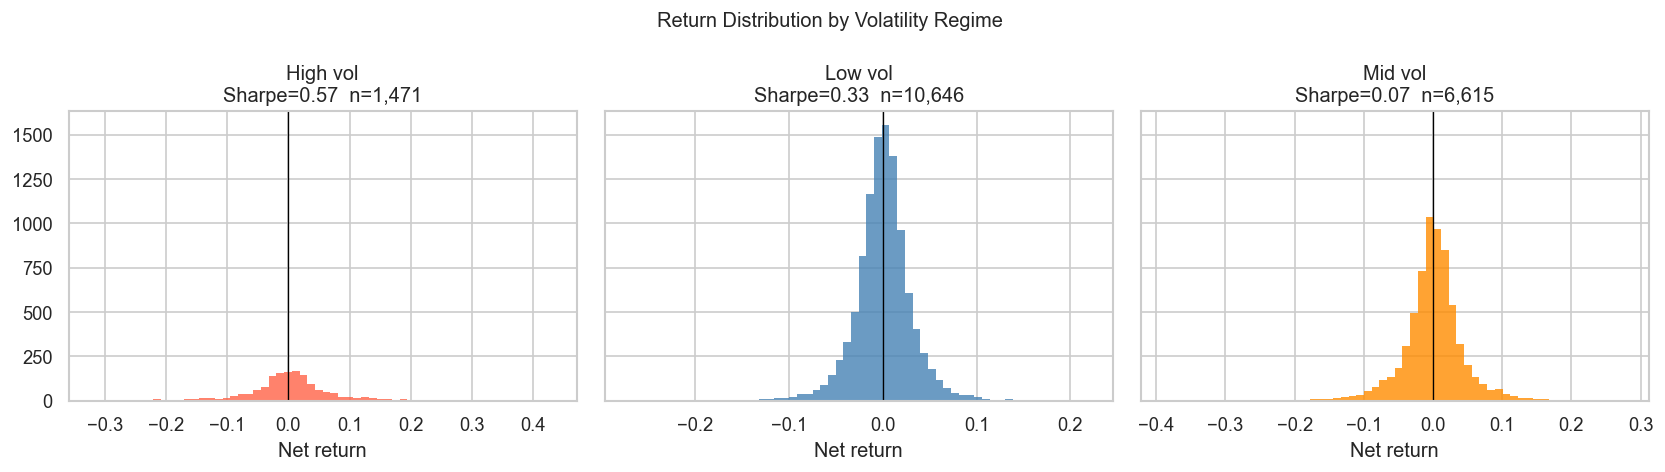

In [3]:
strat_reg = add_volatility_regime(strat, vol_col="volatility_20d", group_col="ticker")

vol_labels = {0: "Low vol", 1: "Mid vol", 2: "High vol"}
strat_reg["vol_regime_label"] = strat_reg["volatility_regime"].map(vol_labels)

vol_perf = performance_by_regime(strat_reg.dropna(subset=["vol_regime_label"]),
                                 regime_col="vol_regime_label")
print("Performance by volatility regime (all tickers pooled):")
print(vol_perf.set_index("regime").round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
regime_colors = {"Low vol": "steelblue", "Mid vol": "darkorange", "High vol": "tomato"}

for ax, (label, group) in zip(axes, strat_reg.groupby("vol_regime_label")):
    r = group["net_return"].dropna()
    ax.hist(r, bins=60, color=regime_colors.get(label, "gray"), alpha=0.8, edgecolor="none")
    sh = sharpe_ratio(r)
    ax.set_title(f"{label}\nSharpe={sh:.2f}  n={len(r):,}")
    ax.set_xlabel("Net return")
    ax.axvline(0, color="black", lw=0.8)

fig.suptitle("Return Distribution by Volatility Regime", fontsize=12)
plt.tight_layout()
plt.show()

## 3. Hurricane season — in-season vs off-season performance

Performance by hurricane season:
        n_obs  mean_return_annualized  sharpe  hit_rate
regime                                                 
0        8606                  0.0597  0.0865    0.5069
1       10126                  0.2416  0.4177    0.5145


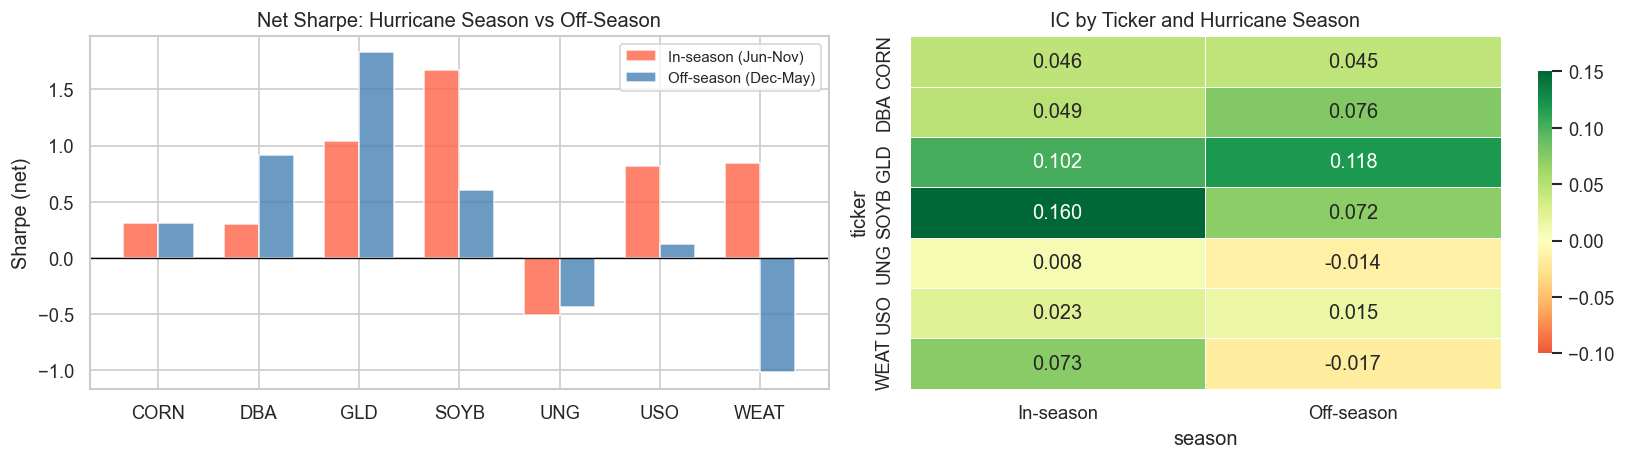

In [4]:
hurr_perf = hurricane_season_performance(strat)
print("Performance by hurricane season:")
print(hurr_perf.set_index("regime").round(4).to_string())

# Per-ticker breakdown
ticker_hurr = []
for tkr in tickers:
    sub = strat[strat["ticker"] == tkr]
    for season_flag, label in [(True, "In-season"), (False, "Off-season")]:
        g = sub[sub["hurricane_season"] == season_flag]["net_return"].dropna()
        if len(g) < 20:
            continue
        ticker_hurr.append({
            "ticker": tkr,
            "season": label,
            "sharpe": round(sharpe_ratio(g), 3),
            "ic":     round(information_coefficient(
                          sub[sub["hurricane_season"] == season_flag]["prediction"].dropna(),
                          sub[sub["hurricane_season"] == season_flag]["actual"].dropna()
                      ), 4),
            "n":      len(g),
        })

hurr_ticker = pd.DataFrame(ticker_hurr)
sharpe_hurr = hurr_ticker.pivot(index="ticker", columns="season", values="sharpe")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Bar chart: Sharpe by season per ticker
x = np.arange(len(tickers))
width = 0.35
ax = axes[0]
in_vals  = sharpe_hurr.get("In-season",  pd.Series([0]*len(tickers), index=tickers)).reindex(tickers).fillna(0)
off_vals = sharpe_hurr.get("Off-season", pd.Series([0]*len(tickers), index=tickers)).reindex(tickers).fillna(0)
ax.bar(x - width/2, in_vals,  width, label="In-season (Jun-Nov)",  color="tomato",    alpha=0.8)
ax.bar(x + width/2, off_vals, width, label="Off-season (Dec-May)", color="steelblue", alpha=0.8)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(tickers)
ax.set_ylabel("Sharpe (net)")
ax.set_title("Net Sharpe: Hurricane Season vs Off-Season")
ax.legend(fontsize=9)

# IC heatmap by ticker × season
ic_hurr = hurr_ticker.pivot(index="ticker", columns="season", values="ic")
sns.heatmap(ic_hurr, annot=True, fmt=".3f", cmap="RdYlGn",
            center=0, vmin=-0.1, vmax=0.15, ax=axes[1],
            linewidths=0.5, cbar_kws={"shrink": 0.8})
axes[1].set_title("IC by Ticker and Hurricane Season")

plt.tight_layout()
plt.show()

## 4. ENSO regime — El Niño / Neutral / La Niña

Performance by ENSO regime (all tickers pooled):
         n_obs  mean_return_annualized  sharpe  hit_rate
regime                                                  
La_Nina   5184                  0.4063  0.6002    0.5226
Neutral   7020                  0.3676  0.6266    0.5158
El_Nino   6528                 -0.2646 -0.4125    0.4966


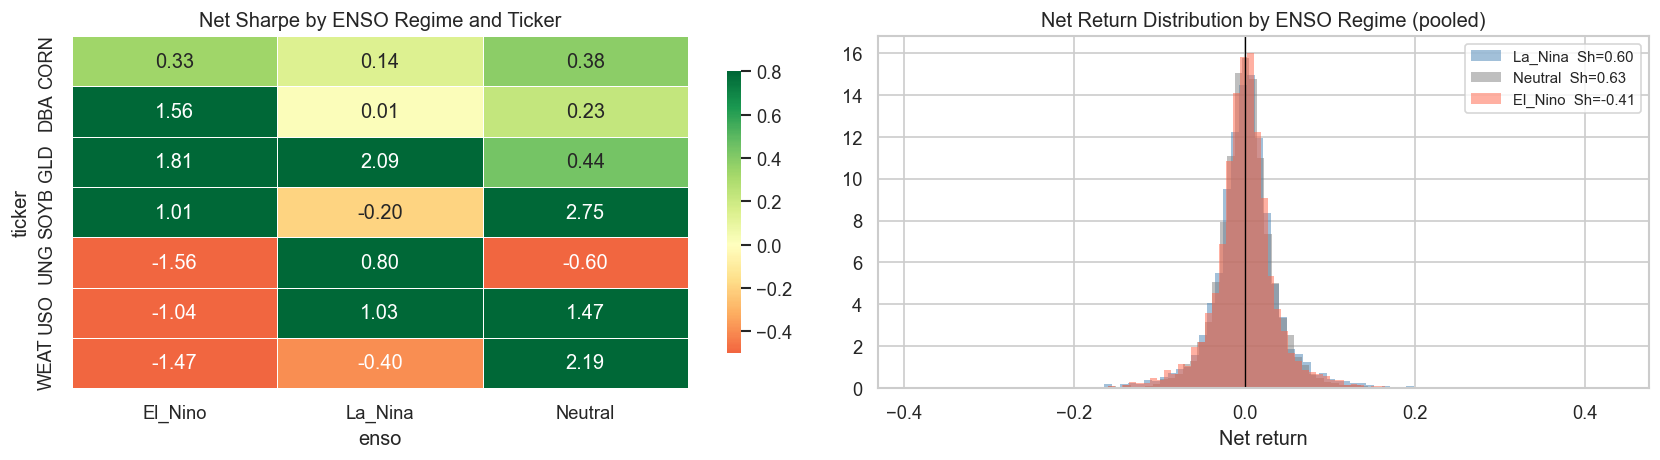

In [5]:
enso_perf = performance_by_regime(strat.dropna(subset=["enso_regime"]),
                                  regime_col="enso_regime")
print("Performance by ENSO regime (all tickers pooled):")
print(enso_perf.set_index("regime").round(4).to_string())

# Ticker × ENSO sharpe matrix
enso_rows = []
for tkr in tickers:
    sub = strat[strat["ticker"] == tkr].dropna(subset=["enso_regime"])
    for regime, g in sub.groupby("enso_regime"):
        r = g["net_return"].dropna()
        if len(r) < 20:
            continue
        enso_rows.append({
            "ticker": tkr,
            "enso":   str(regime),
            "sharpe": round(sharpe_ratio(r), 3),
        })

enso_df = pd.DataFrame(enso_rows)
sharpe_enso = enso_df.pivot(index="ticker", columns="enso", values="sharpe")

enso_colors = {"El_Nino": "tomato", "Neutral": "gray", "La_Nina": "steelblue"}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Heatmap
sns.heatmap(sharpe_enso, annot=True, fmt=".2f", cmap="RdYlGn",
            center=0, vmin=-0.5, vmax=0.8, ax=axes[0],
            linewidths=0.5, cbar_kws={"shrink": 0.8})
axes[0].set_title("Net Sharpe by ENSO Regime and Ticker")

# Pooled return distribution by ENSO
for label, group in strat.groupby("enso_regime"):
    r = group["net_return"].dropna()
    axes[1].hist(r, bins=80, alpha=0.5,
                 color=enso_colors.get(str(label), "gray"),
                 label=f"{label}  Sh={sharpe_ratio(r):.2f}",
                 density=True, edgecolor="none")
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Net Return Distribution by ENSO Regime (pooled)")
axes[1].set_xlabel("Net return")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

## 5. AMO regime — Atlantic Multi-decadal Oscillation phase

Performance by AMO regime (all tickers pooled):
              n_obs  mean_return_annualized  sharpe  hit_rate
regime                                                       
AMO_positive  18732                   0.158    0.25     0.511


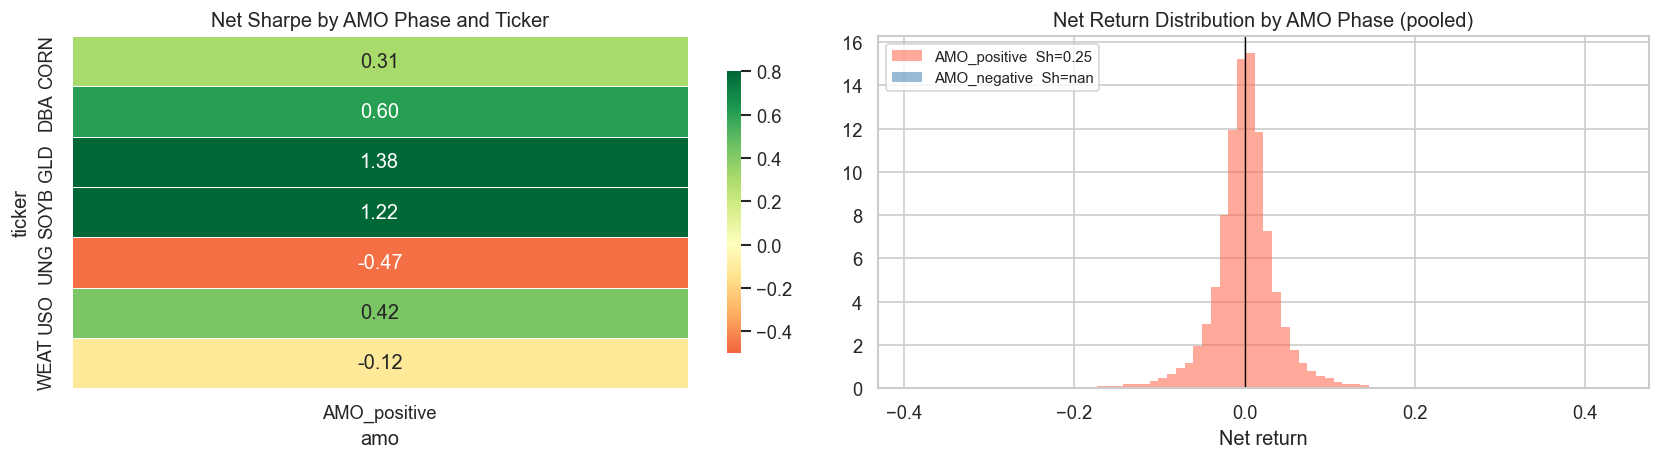

In [6]:
amo_perf = performance_by_regime(strat.dropna(subset=["amo_regime"]),
                                 regime_col="amo_regime")
print("Performance by AMO regime (all tickers pooled):")
print(amo_perf.set_index("regime").round(4).to_string())

# AMO regime Sharpe per ticker
amo_rows = []
for tkr in tickers:
    sub = strat[strat["ticker"] == tkr].dropna(subset=["amo_regime"])
    for regime, g in sub.groupby("amo_regime"):
        r = g["net_return"].dropna()
        if len(r) < 20:
            continue
        amo_rows.append({
            "ticker": tkr,
            "amo":    str(regime),
            "sharpe": round(sharpe_ratio(r), 3),
        })

amo_df     = pd.DataFrame(amo_rows)
sharpe_amo = amo_df.pivot(index="ticker", columns="amo", values="sharpe")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(sharpe_amo, annot=True, fmt=".2f", cmap="RdYlGn",
            center=0, vmin=-0.5, vmax=0.8, ax=axes[0],
            linewidths=0.5, cbar_kws={"shrink": 0.8})
axes[0].set_title("Net Sharpe by AMO Phase and Ticker")

for regime_label, color in [("AMO_positive", "tomato"), ("AMO_negative", "steelblue")]:
    sub = strat[strat["amo_regime"] == regime_label]
    r   = sub["net_return"].dropna()
    axes[1].hist(r, bins=80, alpha=0.55, color=color, density=True,
                 label=f"{regime_label}  Sh={sharpe_ratio(r):.2f}", edgecolor="none")
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Net Return Distribution by AMO Phase (pooled)")
axes[1].set_xlabel("Net return")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

## 6. Cross-regime summary and export

Saved regime_performance.csv
     regime_type       regime     n  sharpe  hit_rate      ic  mean_return
      Volatility     High vol  1471   0.568    0.5438  0.1032       0.6436
      Volatility      Low vol 10646   0.331    0.5200  0.0403       0.1568
      Volatility      Mid vol  6615   0.075    0.5152  0.0316       0.0520
Hurricane Season            0  8606   0.086    0.5164  0.0338       0.0597
Hurricane Season            1 10126   0.418    0.5234  0.0544       0.2416
            ENSO      El_Nino  6528  -0.412    0.5023 -0.0093      -0.2646
            ENSO      La_Nina  5184   0.600    0.5266  0.0639       0.4063
            ENSO      Neutral  7020   0.627    0.5321  0.0784       0.3676
             AMO AMO_positive 18732   0.250    0.5202  0.0450       0.1580


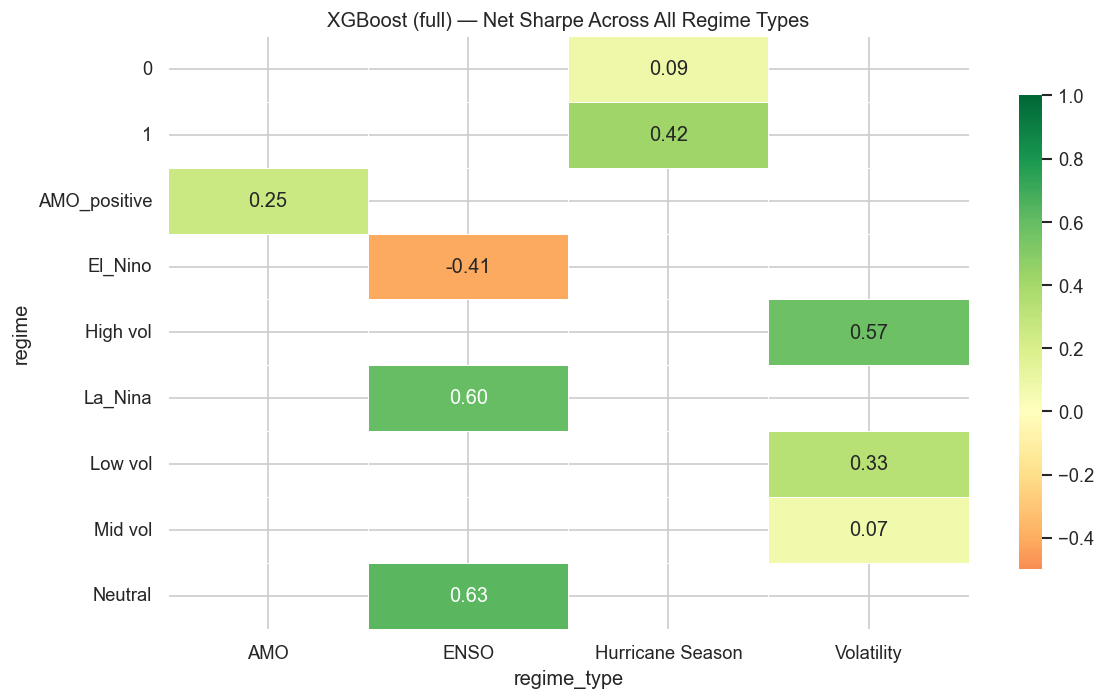

Saved regime_performance.png


In [7]:
all_regime_perf = []

for regime_col, regime_name in [
    ("vol_regime_label", "Volatility"),
    ("hurricane_season", "Hurricane Season"),
    ("enso_regime",      "ENSO"),
    ("amo_regime",       "AMO"),
]:
    tmp = strat_reg if regime_col == "vol_regime_label" else strat
    tmp = tmp.dropna(subset=[regime_col]).copy()
    tmp[regime_col] = tmp[regime_col].astype(str)
    for regime_val, g in tmp.groupby(regime_col):
        r = g["net_return"].dropna()
        if len(r) < 50:
            continue
        p = g.dropna(subset=["prediction", "actual"])
        all_regime_perf.append({
            "regime_type":  regime_name,
            "regime":       regime_val,
            "n":            len(r),
            "sharpe":       round(sharpe_ratio(r), 3),
            "hit_rate":     round(hit_rate(p["prediction"], p["actual"]), 4) if len(p) > 10 else np.nan,
            "ic":           round(information_coefficient(p["prediction"], p["actual"]), 4) if len(p) > 10 else np.nan,
            "mean_return":  round(r.mean() * 252, 4),
        })

regime_summary = pd.DataFrame(all_regime_perf)
regime_summary.to_csv(DATA_PROCESSED_DIR / "regime_performance.csv", index=False)
print("Saved regime_performance.csv")
print(regime_summary.to_string(index=False))

# Combined heatmap of Sharpe across all regime types
fig, ax = plt.subplots(figsize=(10, 6))
pivot_all = regime_summary.pivot(index="regime", columns="regime_type", values="sharpe")
sns.heatmap(pivot_all, annot=True, fmt=".2f", cmap="RdYlGn",
            center=0, vmin=-0.5, vmax=1.0, ax=ax,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
ax.set_title(f"{FOCUS_MODEL} — Net Sharpe Across All Regime Types")
plt.tight_layout()
plt.savefig("../reports/figures/regime_performance.png", dpi=150)
plt.show()
print("Saved regime_performance.png")